# DSA 107 — Lab 4: Getting data from the wild

**Week 4 · w/c 19 October 2026** · paired with DSA 101 lecture week 4

**Name:** Esma Nur Özgökçe **Student ID:** 26022121460

---

### What you will produce

A runnable Colab notebook, pushed to your `dsa107-labs` repository. In it you ask a web service for data, turn its JSON answer into a table, repair the columns, summarise the table and draw one labelled figure from it, and read a table straight off a web page.

### Before you start

Run the setup cell below. If any import fails, run
`!pip install requests pandas matplotlib seaborn lxml` in a new cell and try again.

This lab talks to **real services over the internet**. If one of them does not answer, print the status code first and tell your instructor — do not keep sending the same request.

### How to use this notebook

Every code cell has a **Goal** written just above it. Read the goal, then write the code. You do not need to open the handout while you work — everything you have to do is in this notebook.

Every Goal and every question shows how many **points** it is worth. The table below shows how they add up to the 10 code points.

A code cell only shows the result of its **last line**. If you want to see two or more things from one cell, put each of them inside `print()`.

The **Command reference** below holds the commands you need for this lab, and a few more besides. Read it once now, and come back to it whenever you are stuck.

### How the 10 code points are shared

| Part | Where in this notebook | Points |
| --- | --- | --- |
| Asking the API | Goals 1a, 1b (0.5 each) | 1 |
| From JSON to a table | Goals 2a, 2b (0.75 each) | 1.5 |
| Cleaning | Goal 3a | 1 |
| Group summary | Goal 4a | 1 |
| Figure | Goal 4b (needs an x label, a y label and a title) | 1 |
| Reading a table from a web page | Goals 5a, 5b (0.75 each) | 1.5 |
| Interpretation | Q1, Q2, Q3, Q4 (0.75 each) | 3 |
| **Total** | | **10** |

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from io import StringIO

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
print("pandas", pd.__version__)

pandas 2.2.3


## Command reference

`df` means a whole table (a DataFrame). `s` means a single column (a Series).
Not every command here is needed for this lab — choosing the right one is part of the work.

**Asking a server for data — new this week**

| Command | What it does |
| --- | --- |
| `requests.get(url)` | asks the server at `url` for data, and hands you back a **response** |
| `requests.get(url, headers=headers)` | the same, but also tells the server who you are |
| `requests.get(url, params={"page": 2})` | the same, but adds `?page=2` to the address for you |
| `response.status_code` | `200` it worked · `403` not allowed · `404` wrong address · `429` too many requests |
| `response.json()` | turns a JSON answer into ordinary Python lists and dictionaries |
| `response.text` | gives you the answer as plain text (use this for a web page) |

**Looking at a JSON answer — new this week**

JSON is built from two things. `{ }` is a **dictionary**: named fields, like one row. `[ ]` is a **list**: repeated things, like rows. They sit inside each other, to any depth.

| Command | What it does |
| --- | --- |
| `type(x)` | tells you what `x` is: `list`, `dict`, `str`, `int` … |
| `len(x)` | how many items a list has, or how many fields a dictionary has |
| `x.keys()` | the names of the fields of a dictionary |
| `x[0]` | the **first** item of a list — Python counts from 0 |
| `x["name"]` | the field called `name` of a dictionary |
| `x[1][0]` | the first item of the second item — you can chain them |

**From a JSON tree to a table — new this week**

| Command | What it does |
| --- | --- |
| `pd.DataFrame(records)` | builds a table from a list of **flat** dictionaries |
| `pd.json_normalize(records)` | the same, but also opens up nested dictionaries: a field `region` holding `{"value": "X"}` becomes a column named `region.value` |

**Looking at the table**

| Command | What it does |
| --- | --- |
| `df.head(n)` | returns the first `n` rows (5 if you do not say) |
| `df.tail(n)` | returns the **last** `n` rows |
| `df.shape` | gives (number of rows, number of columns) |
| `len(df)` | gives the number of rows |
| `df.info()` | prints the column names, their types and their non-missing counts |
| `df.isna().sum()` | gives the number of missing values in each column |
| `s.value_counts()` | counts how many times each value appears |
| `s.sort_values(ascending=False)` | sorts from largest to smallest |

**Choosing, renaming and repairing columns — new this week**

| Command | What it does |
| --- | --- |
| `df[["a", "b"]]` | keeps only these columns — note the **double** brackets |
| `df.rename(columns={"old": "new"})` | gives a column a new name |
| `df.dtypes` | what each column is stored as: `object` = text, `int64` / `float64` = numbers |
| `pd.to_numeric(s)` | turns a text column into real numbers |
| `pd.to_numeric(s, errors="coerce")` | the same, but anything that is not a number becomes `NaN` (missing) instead of an error |
| `df["col"] = ...` | puts a column back into the table, replacing the old one |

**Choosing rows — from last week**

| Command | What it does |
| --- | --- |
| `df["col"] == "x"` | a **boolean mask**: for every row, is the value equal to `"x"`? |
| `df["col"] != "x"` | for every row: is the value **not** equal to `"x"`? |
| `df[mask]` | keeps only the rows where the mask is `True` |
| `mask.sum()` | how many rows are `True` |

**Group summaries — from last week**

| Command | What it does |
| --- | --- |
| `df.groupby("g")["x"].count()` | how many rows there are in each group |
| `.mean()` `.median()` `.max()` `.min()` | put one of these in place of `.count()` for another summary |
| `df.groupby(["g1", "g2"])["x"].count()` | one group for every **combination** of `g1` and `g2` |
| `.unstack()` | turns a two-key result into a grid: `g1` down the side, `g2` across the top |
| `grid.sum(axis=1)` | adds up each **row** of a grid and gives one number per row |

**Reading tables off a web page — new this week**

| Command | What it does |
| --- | --- |
| `pd.read_html(StringIO(page.text))` | finds **every** `<table>` on the page and gives you a **list** of DataFrames |
| `len(tables)` | how many tables it found |
| `tables[3]` | picks table number 3 out of the list |
| `t.shape` and `list(t.columns)` | use these on each table to find the one you want |

**Drawing and labelling**

The plot commands hand you back an *axes* object. Catch it in a variable (`ax = ...`) and you can label it.

| Command | What it does |
| --- | --- |
| `plt.figure(figsize=(10, 5))` | makes the **next** figure 10 wide and 5 tall |
| `ax = s.plot.bar()` | draws a bar chart, one bar per row |
| `ax = df.plot.scatter(x="a", y="b")` | draws a scatter plot: one dot per row |
| `ax = sns.scatterplot(data=df, x="a", y="b", hue="g")` | a scatter plot with the dots **coloured** by the groups in `g` |
| `ax.set_xlabel("...")` | names the horizontal axis |
| `ax.set_ylabel("...")` | names the vertical axis |
| `ax.set_title("...")` | puts a title on the figure |
| `ax.legend(title="...", bbox_to_anchor=(1.02, 1), loc="upper left")` | moves the legend **outside** the figure, so it does not cover the dots |
| `plt.show()` | shows the finished figure |

A figure in this course is not finished until it has both axis labels and a title.

## 1. Ask a server for data

In the first three weeks the data was a CSV file waiting at a web address, and `read_csv` loaded it. This week you **ask** for the data instead.

An **API** is a service you can talk to over the internet. You send a request; it sends an answer back. The answer is usually **JSON**, not a table.

This week's service is the **World Bank country API**. For every country in the world it knows which region it is in, which income group the World Bank puts it in, what its capital city is, and where that capital sits on the map.

Two habits start here, and you will keep them for the rest of the course:

- **Check the status code.** `200` means the server understood you and answered. Any other number means stop and look at what you got.
- **Look at the answer before you turn it into a table.** A DataFrame is flat; JSON is a tree. You cannot choose which branch becomes your rows until you have seen the tree.

> **Goal 1a · 0.5 pt.** Send the request (the address is already written for you). Print the **status code**, then turn the answer into Python with `.json()`, store it as `data`, and print `type(data)`.

In [2]:
url = 'https://api.worldbank.org/v2/country?format=json&per_page=400'
response=requests.get(url)
print('Status code:',response.status_code)
data=response.json()
print('Data type:',type(data))

# TODO: send the request and store the answer as response
# TODO: print the status code
# TODO: turn the answer into Python (call it data) and print its type

Status code: 200
Data type: <class 'list'>


> **Goal 1b · 0.5 pt.** Look at the answer before you turn it into a table. Print how many parts `data` has, then print the **first part** on its own. Then print how many records are in the **second part**, and show the **first record** of it.
> The first record is a dictionary. Read its field names — those will become your columns.

In [4]:
# TODO: print how many parts data has
# TODO: print the first part (data[0])
# TODO: print how many records are in the second part (data[1])
# TODO: show the first record of the second part
print('Number of parts in data:',len(data))
print('first part(metadata)',data[0])
print('Number of records in the second part:',len(data[1]))
print('First record of the second part:')
print(data[1][0])

Number of parts in data: 2
first part(metadata) {'page': 1, 'pages': 1, 'per_page': '400', 'total': 296}
Number of records in the second part: 296
First record of the second part:
{'id': 'ABW', 'iso2Code': 'AW', 'name': 'Aruba', 'region': {'id': 'LCN', 'iso2code': 'ZJ', 'value': 'Latin America & Caribbean '}, 'adminregion': {'id': '', 'iso2code': '', 'value': ''}, 'incomeLevel': {'id': 'HIC', 'iso2code': 'XD', 'value': 'High income'}, 'lendingType': {'id': 'LNX', 'iso2code': 'XX', 'value': 'Not classified'}, 'capitalCity': 'Oranjestad', 'longitude': '-70.0167', 'latitude': '12.5167'}


**Q1 · 0.75 pt.**
(a) What status code did the server send back, and what does that number mean?
(b) The answer has two parts. What is in the first part, and what is in the second part?
(c) How many records did the server say there are in total, and how many did you actually get? Are those two numbers the same, and why?

(a) The server returned status code 200, which means the HTTP request was successful and the server returned the requested data.

(b) The first part contains API response metadata (pagination info: current page, total pages, per_page, and total record count). The second part contains the actual list of country and territory records as dictionaries.

(c) The server stated there are 296 total records, and we received 296 records. The two numbers are identical because `per_page=400` was specified in the URL parameters, which exceeds the total record count and allows all entries to be retrieved in a single response page.

## 2. From a JSON tree to a table

`pd.DataFrame()` works when the records are a **flat** list of dictionaries. These records are not flat: the field `region` is itself a small dictionary, with `id`, `iso2code` and `value` inside it.

`pd.json_normalize()` deals with that. It walks into the nested dictionaries and makes one column for every leaf, joining the names with a dot — the `value` inside `region` becomes a column called **`region.value`**.

What you get back is a wide table with names you did not choose. So the next step is always the same: **keep the columns you need, and give them names you can type.**

> **Goal 2a · 0.75 pt.** Build a DataFrame called `countries_raw` from the **records** (the second part of `data`) with `pd.json_normalize`. Print its shape, then show the first five rows.

In [5]:
# Build countries_raw from the records (data[1]) with json_normalize
countries_raw = pd.json_normalize(data[1])

# Print its shape, then show the first five rows
print("Shape of countries_raw:", countries_raw.shape)
display(countries_raw.head())

Shape of countries_raw: (296, 18)


,id,iso2Code,name,capitalCity,longitude,latitude,region.id,region.iso2code,region.value,adminregion.id,adminregion.iso2code,adminregion.value,incomeLevel.id,incomeLevel.iso2code,incomeLevel.value,lendingType.id,lendingType.iso2code,lendingType.value
0,ABW,AW,Aruba,Oranjestad,-70.0167,12.5167,LCN,ZJ,Latin America & Caribbean,,,,HIC,XD,High income,LNX,XX,Not classified
1,AFE,ZH,Africa Eastern and Southern,,,,NA,NA,Aggregates,,,,NA,NA,Aggregates,,,Aggregates
2,AFG,AF,Afghanistan,Kabul,69.1761,34.5228,MEA,ZQ,"Middle East, North Africa, Afghanistan & Pakistan",MNA,XQ,"Middle East, North Africa, Afghanistan & Pakis...",LIC,XM,Low income,IDX,XI,IDA
3,AFR,A9,Africa,,,,NA,NA,Aggregates,,,,NA,NA,Aggregates,,,Aggregates
4,AFW,ZI,Africa Western and Central,,,,NA,NA,Aggregates,,,,NA,NA,Aggregates,,,Aggregates


> **Goal 2b · 0.75 pt.** Keep only the seven columns listed below and store the result as `countries`. Then **rename** the two columns that have a dot in their name: `region.value` → `region` and `incomeLevel.value` → `income_level`.
> Now print `countries.dtypes` and look at `longitude` and `latitude`. Turn both of them into real numbers with `pd.to_numeric(..., errors="coerce")`, put them back into the table, and print `countries.dtypes` again.

In [6]:
keep = ["id", "name", "capitalCity", "longitude", "latitude", "region.value", "incomeLevel.value"]

# Keep those columns and rename the two with a dot in their name; call the result countries
countries = countries_raw[keep].rename(columns={
    "region.value": "region",
    "incomeLevel.value": "income_level"
})

# Print the dtypes BEFORE you change anything
print("--- dtypes before conversion ---")
print(countries.dtypes)

# Turn longitude and latitude into numbers with errors="coerce"
countries["longitude"] = pd.to_numeric(countries["longitude"], errors="coerce")
countries["latitude"] = pd.to_numeric(countries["latitude"], errors="coerce")

# Print the dtypes AFTER
print("\n--- dtypes after conversion ---")
print(countries.dtypes)

--- dtypes before conversion ---
id              object
name            object
capitalCity     object
longitude       object
latitude        object
region          object
income_level    object
dtype: object

--- dtypes after conversion ---
id               object
name             object
capitalCity      object
longitude       float64
latitude        float64
region           object
income_level     object
dtype: object


**Q2 · 0.75 pt.**
(a) How many rows and how many columns did `json_normalize` give you, and what does one row stand for?
(b) Look at the dtypes you printed **before** the change. What were `longitude` and `latitude` stored as? Why would that be a problem if you wanted to draw them on a figure?

(a)By this code, we have 296 rows and 18 columns. A one row reperesents an individual country, territory, or regional aggregate entity tracked by the World Bank.

(b) Before conversion, longtitude and latitude were stored as object. Storing geographic coordinates as strings prevents performing mathematical computations and distance measurements.

## 3. Not every row is a country

The list has 296 rows, but there are not 296 countries in the world. Along with the countries, the World Bank list holds **aggregates**: rows such as *Africa Eastern and Southern*, *Euro area* or *World*, which are **groups** of countries rather than countries.

Every aggregate has the word `Aggregates` in its `region` column.

If you leave them in, you will count them as countries and every answer after this point will be wrong. Last week's **boolean mask** is exactly the right tool.

> **Goal 3a · 1 pt.** Print how many rows `countries` has now. Then keep only the rows whose `region` is **not** `"Aggregates"`, store the result back in `countries`, and print how many rows are left. Finally, print how many values are missing in each column.

In [7]:
# TODO: print the number of rows before
print('The number of rows before:', len(countries))
# TODO: keep only the rows that are real countries
countries=countries[countries['region']!='Aggregates'].copy()
# TODO: print the number of rows after
print('The number of rows after:',len(countries))
# TODO: print how many values are missing in each column
print('\nMissing values in each column')
print(countries.isna().sum())

The number of rows before: 296
The number of rows after: 217

Missing values in each column
id              0
name            0
capitalCity     0
longitude       6
latitude        6
region          0
income_level    0
dtype: int64


## 4. Summarise it, and draw it

The data is yours now, so the rest is last week's work: **split, apply, combine**, and one labelled figure.

The figure is a scatter plot of `longitude` against `latitude`. That is only two numbers per capital city. But if you draw two hundred of them at once, you will see something familiar.

> **Goal 4a · 1 pt.** Count how many countries there are for every combination of `region` and `income_level`. Use `.unstack()` so that `region` runs down the side and `income_level` runs across the top. Store it as `by_two` and show it.
> An empty cell shows `NaN`. It means there is no country in that combination.

In [9]:
# TODO: count the countries for every region and income_level combination, as a grid, stored as by_two
by_two=countries.groupby(['region','income_level'])['id'].count().unstack()
by_two

income_level,High income,Low income,Lower middle income,Upper middle income
region,,,,
East Asia & Pacific,15.0,1.0,8.0,13.0
Europe & Central Asia,40.0,NaN,3.0,15.0
Latin America & Caribbean,19.0,NaN,5.0,18.0
"Middle East, North Africa, Afghanistan & Pakistan",8.0,3.0,7.0,5.0
North America,3.0,NaN,NaN,NaN
South Asia,NaN,NaN,4.0,2.0
Sub-Saharan Africa,1.0,21.0,20.0,6.0


> **Goal 4b · Figure · 1 pt.** Draw a scatter plot with `longitude` on the x-axis and `latitude` on the y-axis, with the dots **coloured by `region`**. Give it an x label, a y label and a title, and move the legend outside the figure so that it does not cover the dots (there is a line for that in the Command reference).

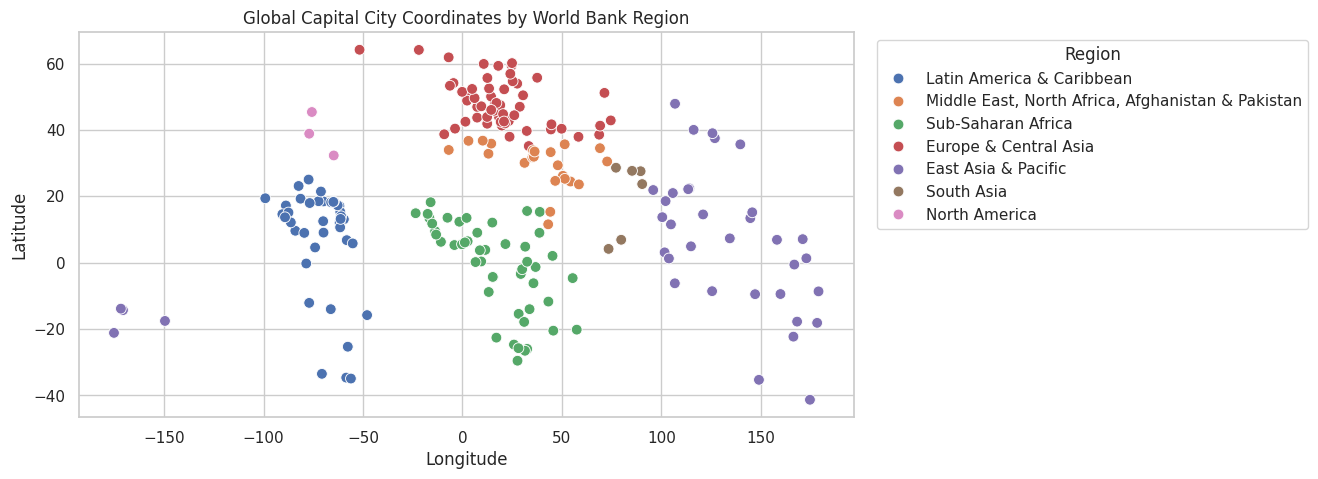

In [13]:
plt.figure(figsize=(10, 5))
#plt.figure(figsize=(10,9)),increases the plot's vertical height from 5 to 9 inches, making the scatter plot look taller and less wide while giving the latitude axis more space.

# Scatter plot of longitude against latitude coloured by region
ax = sns.scatterplot(
    data=countries,
    x="longitude",
    y="latitude",
    hue="region",
    s=60
)

# Label axes, add title, and position legend outside plot area
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Global Capital City Coordinates by World Bank Region")
ax.legend(title="Region", bbox_to_anchor=(1.02, 1), loc="upper left")


# TODO: scatter plot of longitude (x) against latitude (y), coloured by region
# TODO: x label, y label, title, and move the legend outside

plt.show()

**Q3 · 0.75 pt.**
(a) Add up each row of `by_two` (an empty `NaN` cell adds nothing). Which region has the most countries in total, and which has the fewest? Give both numbers.
(b) Find one `NaN` in `by_two` and name the combination it belongs to. What does `NaN` mean here — zero countries, or something else?
(c) Look at your figure. Name one thing the picture tells you that the `by_two` grid cannot.

(a) Summing each row of by_two: Europe & Central Asia has the most countries in total with 58, while North America has the fewest with 3.

(b) An example of NaN in by_two occurs at the combination of North America and Low income. Here, `NaN` represents exactly zero countries fitting that specific category pair.

(c) The scatter plot reveals spatial geographic patterns, global distributions, and physical clustering of capital cities that resemble a world map, which the tabular summary grid by_two cannot show.

## 5. A table that is already sitting on a web page

Not everything has an API. Very often the numbers you want are already in a table on a web page, drawn for human eyes rather than for your code.

A web page is a tree as well, written in HTML: a `<table>` holds `<tr>` rows, which hold `<td>` cells. `pd.read_html` walks that tree for you and turns **every** table on the page into a DataFrame.

Two warnings before you start:

- It hands you a **list**, not a table. A page can hold a dozen tables, and most of them are menus and boxes you do not want. Print the shape of each one and find yours. Never guess the number.
- What comes back is **dirty**. Numbers often arrive as text, and footnote markers stick to values. Cleaning that is next week's lecture. Today you only have to notice it.

(`read_html` only finds real `<table>` tags. When a page has none, you need BeautifulSoup, which the lecture showed. You do not need it this week.)

One more thing: **say who you are.** `headers` carries your name to the server. It is polite, and it is practical — some sites refuse requests that do not identify themselves.

> **Goal 5a · 0.75 pt.** Put your own name and e-mail into `headers`. Fetch the page with `requests.get(..., headers=headers)`, store the answer as `page`, and print the status code. Then read **every** table on the page into a list called `tables` and print how many tables there are. The loop that lists them is written for you.

In [16]:
wiki_url = "https://en.wikipedia.org/wiki/List_of_countries_by_Human_Development_Index"

headers = {"User-Agent": 'DSA107 student lab - Esma Nur Özgökçe - e.ozgokce2024@gtu.edu.tr'}


page = requests.get(wiki_url, headers=headers)
print("Status code:", page.status_code)


tables = pd.read_html(StringIO(page.text))
print(f"Found {len(tables)} tables on the page.\n")


for i, t in enumerate(tables):
    print(i, t.shape, list(t.columns)[:3])

Status code: 200
Found 14 tables on the page.

0 (3, 3) ['Dimensions', 'Indicators', 'Dimension index']
1 (193, 5) ['Rank', 'Change since 2015', 'Country or territory']
2 (15, 10) ['Region or group', '1990', '2000']
3 (17, 2) ['vteDeprivation and poverty indicators', 'vteDeprivation and poverty indicators.1']
4 (2, 2) [0, 1]
5 (1, 2) [0, 1]
6 (2, 2) [0, 1]
7 (2, 2) [0, 1]
8 (2, 2) [0, 1]
9 (13, 2) ['vteEconomic classification of countries', 'vteEconomic classification of countries.1']
10 (2, 2) [0, 1]
11 (13, 2) ['vteLists of countries by population statistics', 'vteLists of countries by population statistics.1']
12 (6, 2) ['vteLists of countries by quality of life rankings', 'vteLists of countries by quality of life rankings.1']
13 (8, 2) ['vteLists of subnational entities by Human Development Index rankings', 'vteLists of subnational entities by Human Development Index rankings.1']


> **Goal 5b · 0.75 pt.** Pick the Human Development Index table out of the list — the long one, with one row per country — and store it as `hdi`. Print `hdi.dtypes`, then print the first five rows **and the last five rows**. Look at both ends: the bottom of a web table is often messier than the top.

In [17]:
# Pick the right table out of the list and call it hdi
hdi = tables[1]

# Print hdi.dtypes
print("--- hdi columns and dtypes ---")
print(hdi.dtypes)

# Print the first five rows, then the last five rows
print("\n--- First 5 rows ---")
display(hdi.head())

print("\n--- Last 5 rows ---")
display(hdi.tail())

--- hdi columns and dtypes ---
Rank                             int64
Change since 2015               object
Country or territory            object
HDI value                      float64
% annual growth (2010–2023)     object
dtype: object

--- First 5 rows ---


,Rank,Change since 2015,Country or territory,HDI value,% annual growth (2010–2023)
0,1,(2),Iceland,0.972,0.28%
1,2,(1),Norway,0.970,0.25%
2,2,NaN,Switzerland,0.970,0.24%
3,4,(2),Denmark,0.962,0.35%
4,5,(1),Germany,0.959,0.19%



--- Last 5 rows ---


,Rank,Change since 2015,Country or territory,HDI value,% annual growth (2010–2023)
188,188,(3),Niger,0.419,1.34%
189,190,(1),Chad,0.416,0.66%
190,191,(1),Central African Republic,0.414,0.58%
191,192,N/A[b],Somalia,0.404,N/A[b]
192,193,NaN,South Sudan,0.388,0.61%


**Q4 · 0.75 pt.**
(a) How many tables did `read_html` find on that page, and which one did you keep? How did you decide it was the right one?
(b) Look at the dtypes of `hdi`. One column holds percentages. What is it stored as, and why is it not a number?
(c) Name one other thing in this table that would have to be cleaned before you could use it.

(a) 'read_htm'found several tables on the page. We kept the main HDI table because it was the longest table (with over 150 rows) and contained the list of countries.

(b) It is stored as an 'object'. It is not a number because it contains extra characters like percentage signs and symbols.

(c) We need to clean footnote marks attached to the text before using the data.

## 6. Push to GitHub

1. You created a repository named `dsa107-labs` in Lab 1. Use the same one.
2. In Colab: **File → Save a copy in GitHub**, and choose that repository.
3. Paste the resulting link in the line below.

**Repository link:**

---

## Submission checklist

- [ ] Every cell runs top to bottom without error (Runtime → Restart and run all)
- [ ] The figure (Goal 4b) has an x label, a y label and a title
- [ ] All four written answers (Q1–Q4) are filled in — a figure or a table with no reading of it scores zero on interpretation
- [ ] Notebook saved as `Lab04_Firstname_Lastname.ipynb`
- [ ] If you used an AI assistant, the log is attached as described in the course AI policy

Submit both files through MS Teams.

what can ı do in the goal 2a
In Goal 2a, your task is to turn the nested JSON records we fetched from the World Bank API into a structured pandas DataFrame using pd.json_normalize().

Remember from Goal 1b that our actual country records are stored in the second part of data (which is data[1]).

I will generate the cell to complete this step and show you the first 5 rows of the normalized table.

In Goal 2b, you need to:

Select only the seven columns listed in keep and assign the result to countries.
Rename region.value to region and incomeLevel.value to income_level.
Print the data types (countries.dtypes) before modifying them.
Convert the longitude and latitude columns into numeric types using pd.to_numeric(..., errors='coerce') and put them back in the table.
Print the data types again to confirm they are now floats.
I will fill in the code cell below to do this for you.


ı cant continue goal 2b what can ı do
The code in cell 1dbdd7f6 has a syntax error because of the incomplete rename() command. I have fixed that cell and written the full code to correctly complete Goal 2b.

Here is what this code does for you:

It slices the countries_raw DataFrame to keep only the columns listed in keep.
It renames the columns containing dots (region.value to region and incomeLevel.value to income_level).
It prints the original data types (countries.dtypes).
It uses pd.to_numeric with errors='coerce' to safely convert longitude and latitude from text objects to decimal numbers (floats).
It prints the data types again to confirm they successfully changed to float64.
Goal 2b has successfully executed! Both longitude and latitude have been converted from object (text) to float64 (numeric) types.

Now, you can answer Q2 using these insights:

(a) json_normalize gave us 296 rows and 18 columns. Each row represents a specific geographic/political entity, which can be either an individual country/territory or a regional/global aggregate of multiple countries.

(b) Before the conversion, longitude and latitude were stored as object types (which means they were treated as plain text strings). This is a problem because plotting libraries (like Matplotlib and Seaborn) cannot plot text values numerically on an axis; they need numeric values (like floats or integers) to position the data points correctly on the graph.


why we use id in goal 4a
In Goal 4a, we use ['id'] because we want to count the number of countries in each group.

Here is how that works in detail:

Grouping: When you run countries.groupby(['region','income_level']), pandas splits the rows of the table into unique combinations of region and income level (for example, Sub-Saharan Africa & Low income).
Selecting a Column: By specifying ['id'] right after the groupby, we tell pandas to look specifically at the id column (which contains unique 3-letter country codes like ABW, AFG, etc.) for the rows in each group.
Counting: Calling .count() then counts how many non-null values exist in that id column for each group.
Since every country in our dataset has a valid, non-null id, counting the id column is a safe and standard way to find the exact number of countries belonging to each region and income level combination.


which codes can ı use in goal 5a
In Goal 5a, you need to fetch the Wikipedia page using requests.get() with custom headers, load all the HTML tables on the page using pd.read_html(), and inspect how many tables were found and what their shapes are.

Make sure to update the User-Agent string with your real name and email address! I will write the complete code in cell 52c957e3.

Great job! Table 1 has a shape of (193, 5) and columns for Rank, Change since 2015, and Country or territory. This is exactly the main Human Development Index table listing individual countries.

I will now write the code in cell 6b689bfe for Goal 5b to:

Extract this table as hdi (using tables[1]).
Print its column data types (hdi.dtypes).
Display the first 5 rows and the last 5 rows.
Goal 5b has executed successfully! Now you are ready to write the answer to Q4 in cell 62695c66. Here are the insights to write down:

(a) read_html found 14 tables on that Wikipedia page. We kept the table at index 1 (tables[1]) because its shape (193, 5) perfectly matches the number of recognized countries/territories in the world, and its column headers (Rank, Country or territory, HDI value) explicitly contain the main Human Development Index data.

(b) The percentage column (% annual growth (2010–2023)) is stored as an object type (text). This is because it contains percentage signs (%) and text markers like 'N/A[b]', which prevent pandas from recognizing it automatically as a numeric float.

(c) Another thing that would need to be cleaned in this table is the Change since 2015 or Country or territory column, as they contain Wikipedia footnote links (such as [b]) and brackets (like (2) or (1)) attached to the values. These must be stripped out before using the data for analysis.